# Lab 8


## Setup for SUSY Dataset

Use the SUSY dataset for the rest of this lab. Here is a basic setup. It reads the full file you downloaded in Lab 7 (5 million rows, about 760 MB in memory once loaded). If your computer struggles, read `../Lab.7/SUSY-small.csv` instead (the first 500,000 rows) and divide the sample sizes below by ten.

`RawNames` are the 8 quantities measured directly; `FeatureNames` are the 10 derived from them, which the physicists designed to separate signal from background. You will need both in Exercise 3.

In [1]:
# Our usual libraries...
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import HTML, display
import tabulate

In [2]:
filename="../Lab.7/SUSY-small.csv"
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", 
          "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET",
          "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=[v for v in VarNames[1:] if v not in RawNames]
df = pd.read_csv(filename, dtype='float64', names=VarNames)

In [2]:
import os

filename = "../Lab.7/SUSY-small.csv"

print("File exists:", os.path.exists(filename))

if os.path.exists(filename):
    print("File size (GB):", round(os.path.getsize(filename) / (1024**3), 2))

File exists: True
File size (GB): 0.22


## Scikit-Learn

[Scikit-learn](https://scikit-learn.org) is a rich python library for data science, including machine learning. For example, we can build a Fisher Discriminant (aka Linear Discriminant Analysis, or LDA). 

### Exercise 1: Install Scikit-Learn

`scikit-learn` is in the course `requirements.txt`, so it should already be in your environment: check that `import sklearn` works. If it doesn't, follow the [Installation Instructions](https://scikit-learn.org/stable/install.html).

In [7]:
import sklearn

print(sklearn.__version__)

1.6.1


### Exercise 2: Read About Classifiers

#### Part a
Scikit-learn offers an impressively comprehensive list of machine learning algorithms. Browse through [scikit-learn's documentation](https://scikit-learn.org/stable/index.html). You'll note the algorithms are organized into classification, regression, clustering, dimensionality reduction, model selection, and preprocessing. Browse through the list of [classification algorithms](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning). 

#### Part b
Note scikit-learn's documentation is rather comprehensive. The documentation on [linear models](https://scikit-learn.org/stable/modules/linear_model.html) shows how classification problems are setup. Read about the first few methods and try to comprehend the example codes. Skim the rest of the document.

#### Part c
Read through the [LDA Documentation](https://scikit-learn.org/stable/modules/lda_qda.html).


### Exercise 3: Training a Classifier

Let's repeat what we did by hand in the previous lab (Lab 7, Exercise 8) using scikit-learn. We'll use an LDA classifier, which we can instantiate as follows:

In [3]:
import sklearn.discriminant_analysis as DA
Fisher=DA.LinearDiscriminantAnalysis()

As discussed in the lecture, to properly formulate our problem, we'll have to:

* Define the inputs (X) vs outputs (Y)
* Designate training vs testing samples (in order to get an unbiased assessment of the performance of machine learning algorithms)

For example, here we'll use 4M events for training and the remainder for testing.

In [4]:
N_Train=4000000

Train_Sample=df[:N_Train]
Test_Sample=df[N_Train:]

X_Train=Train_Sample[VarNames[1:]]
y_Train=Train_Sample["signal"]

X_Test=Test_Sample[VarNames[1:]]
y_Test=Test_Sample["signal"]

Test_sig=Test_Sample[Test_Sample.signal==1]
Test_bkg=Test_Sample[Test_Sample.signal==0]


We can train the classifier as follows:

In [5]:
Fisher.fit(X_Train,y_Train)

LinearDiscriminantAnalysis()

We can plot the output, comparing signal and background:

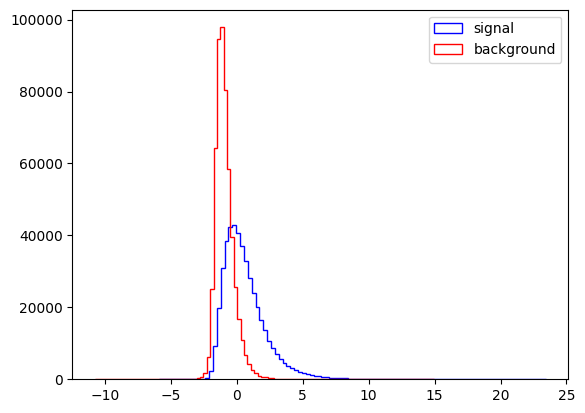

In [6]:
plt.figure()
plt.hist(Fisher.decision_function(Test_sig[VarNames[1:]]),bins=100,histtype="step", color="blue", label="signal",stacked=True)
plt.hist(Fisher.decision_function(Test_bkg[VarNames[1:]]),bins=100,histtype="step", color="red", label="background",stacked=True)
plt.legend(loc='upper right')
plt.show()

#### Part a

Compare the ROC curves computed on the test and on the training samples, in a single plot. Do you see a bias? (Use `Fisher.decision_function` on each sample, and `roc_curve` as in Exercise 5.)

In [8]:
import sklearn.discriminant_analysis as DA
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

Fisher = DA.LinearDiscriminantAnalysis()

In [9]:
N_Train = 400000

Train_Sample = df[:N_Train]
Test_Sample = df[N_Train:]

X_Train = Train_Sample[VarNames[1:]]
y_Train = Train_Sample["signal"]

X_Test = Test_Sample[VarNames[1:]]
y_Test = Test_Sample["signal"]

Test_sig = Test_Sample[Test_Sample.signal == 1]
Test_bkg = Test_Sample[Test_Sample.signal == 0]

In [10]:
Fisher.fit(X_Train, y_Train)

LinearDiscriminantAnalysis()

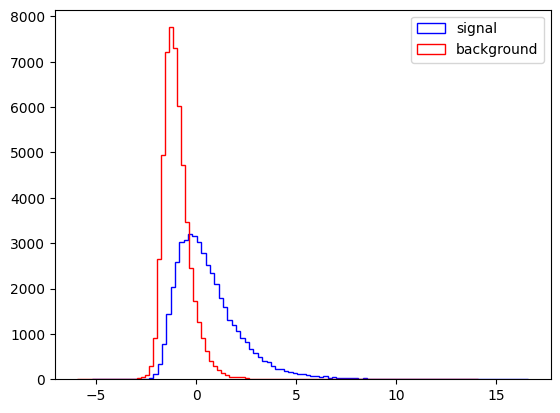

In [11]:
plt.figure()

plt.hist(Fisher.decision_function(Test_sig[VarNames[1:]]), bins=100, histtype="step", color="blue", label="signal")
plt.hist(Fisher.decision_function(Test_bkg[VarNames[1:]]), bins=100, histtype="step", color="red", label="background")

plt.legend(loc="upper right")
plt.show()

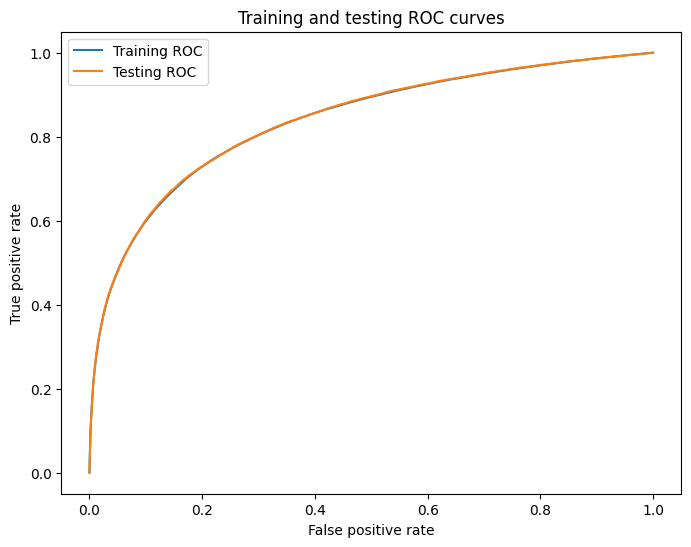

Training AUC: 0.8374834743394474
Testing AUC: 0.8384280007172723


In [12]:
Train_Score = Fisher.decision_function(X_Train)
Test_Score = Fisher.decision_function(X_Test)

fpr_train, tpr_train, thresholds_train = roc_curve(y_Train, Train_Score)
fpr_test, tpr_test, thresholds_test = roc_curve(y_Test, Test_Score)

auc_train = auc(fpr_train, tpr_train)
auc_test = auc(fpr_test, tpr_test)

plt.figure(figsize=(8, 6))

plt.plot(fpr_train, tpr_train, label="Training ROC" % auc_train)
plt.plot(fpr_test, tpr_test, label="Testing ROC" % auc_test)

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Training and testing ROC curves")
plt.legend()
plt.show()

print("Training AUC:", auc_train)
print("Testing AUC:", auc_test)

#### Part b

Train three Fisher discriminants, using as input (1) only the raw quantities (`RawNames`), (2) only the derived features (`FeatureNames`), and (3) all 18. Compare their ROC curves, computed on the test sample, in a single plot. Which inputs carry the separation?

In [13]:
Fisher_Raw = DA.LinearDiscriminantAnalysis()
Fisher_Feature = DA.LinearDiscriminantAnalysis()
Fisher_All = DA.LinearDiscriminantAnalysis()
Fisher_Raw.fit(X_Train[RawNames], y_Train)
Fisher_Feature.fit(X_Train[FeatureNames], y_Train)
Fisher_All.fit(X_Train[VarNames[1:]], y_Train)

LinearDiscriminantAnalysis()

In [14]:
Score_Raw = Fisher_Raw.decision_function(X_Test[RawNames])
Score_Feature = Fisher_Feature.decision_function(X_Test[FeatureNames])
Score_All = Fisher_All.decision_function(X_Test[VarNames[1:]])
fpr_raw, tpr_raw, thresholds_raw = roc_curve(y_Test, Score_Raw)
fpr_feature, tpr_feature, thresholds_feature = roc_curve(y_Test, Score_Feature)
fpr_all, tpr_all, thresholds_all = roc_curve(y_Test, Score_All)

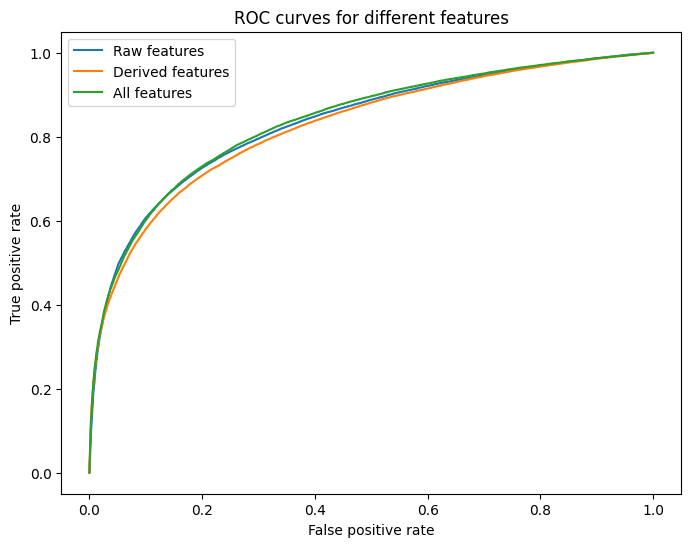

In [15]:
plt.figure(figsize=(8, 6))
plt.plot(fpr_raw, tpr_raw, label="Raw features" % auc(fpr_raw, tpr_raw))
plt.plot(fpr_feature, tpr_feature, label="Derived features" % auc(fpr_feature, tpr_feature))
plt.plot(fpr_all, tpr_all, label="All features" % auc(fpr_all, tpr_all))
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves for different features")
plt.legend()
plt.show()

### Exercise 4: Comparing Techniques

#### Part a
Select 3 different classifiers from the techniques listed [here](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning) to compare. Note that you can use the multi-layer perceptron to build a deep network, though training may be prohibitively slow. So avoid this technique.

#### Part b

Write a function that takes an instantiated classifier and performs the comparison from Exercise 3b. Use the function on each of the classifiers you chose in part a.

#### Part c

Use the best method from part b to compute the maximal significance $\sigma_S= \frac{N_S}{\sqrt{N_S+N_B}}$ for the four scenarios in Lab 7 (Exercise 5.3), choosing the cut on the classifier's output that maximizes it.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.base import clone

In [20]:
def compare_classifier(model):
    models = {
        "Raw features": RawNames,
        "Derived features": FeatureNames,
        "All features": VarNames[1:]
    }

    plt.figure(figsize=(8, 6))

    for name, features in models.items():
        clf = clone(model)
        clf.fit(X_Train[features], y_Train)

        scores = clf.predict_proba(X_Test[features])[:, 1]

        fpr, tpr, thresholds = roc_curve(y_Test, scores)
        score_auc = auc(fpr, tpr)

        plt.plot(fpr, tpr, label=name + " (%.3f)" % score_auc)

        print(name, "AUC:", round(score_auc, 4))

    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(type(model).__name__)
    plt.legend()
    plt.show()

Raw features AUC: 0.8327
Derived features AUC: 0.8349
All features AUC: 0.8587


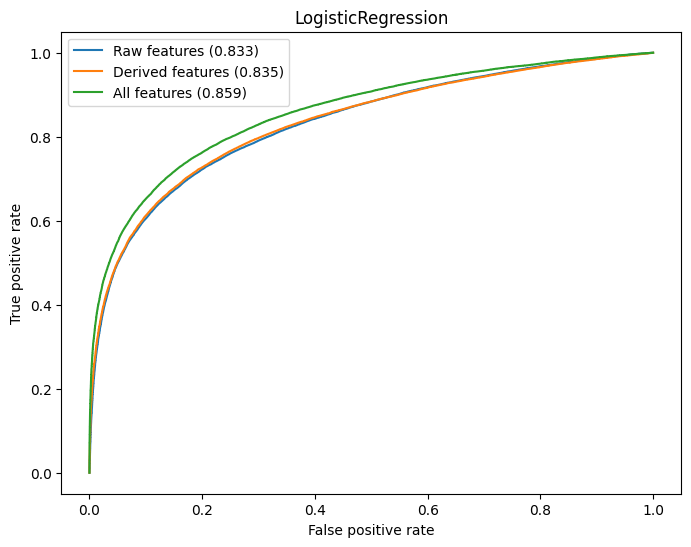

Raw features AUC: 0.8546
Derived features AUC: 0.8574
All features AUC: 0.8654


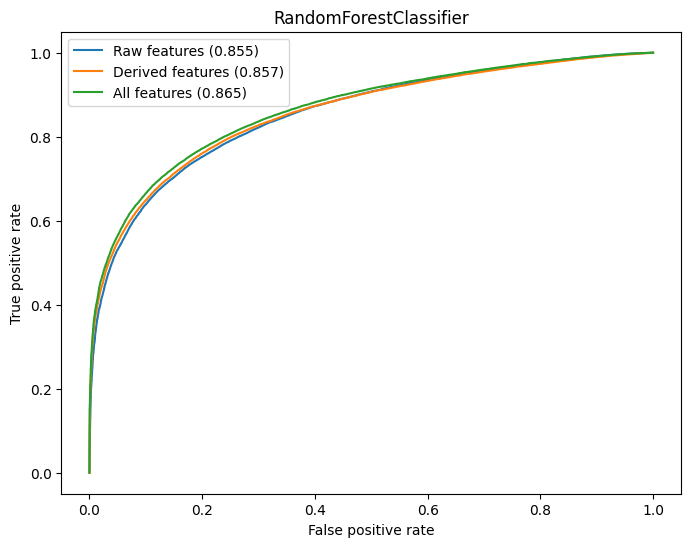

Raw features AUC: 0.8619
Derived features AUC: 0.8634
All features AUC: 0.8755


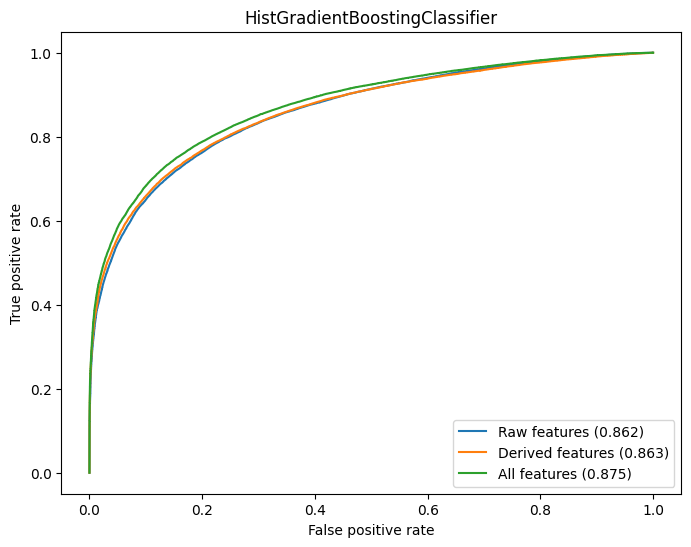

In [21]:
Logistic = LogisticRegression(max_iter=1000)
compare_classifier(Logistic)

Forest = RandomForestClassifier(n_estimators=50, max_depth=10, n_jobs=-1, random_state=42)
compare_classifier(Forest)

Boosting = HistGradientBoostingClassifier(max_iter=100, random_state=42)
compare_classifier(Boosting)

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
from sklearn.base import clone

def plot_significance(model, features):

    clf = clone(model)
    clf.fit(X_Train[features], y_Train)

    scores = clf.predict_proba(X_Test[features])[:, 1]

    fpr, tpr, thresholds = roc_curve(y_Test, scores)

    valid = np.isfinite(thresholds)

    fpr = fpr[valid]
    tpr = tpr[valid]
    thresholds = thresholds[valid]

    scenarios = [
        (10, 100, "Scenario 1"),
        (100, 1000, "Scenario 2"),
        (1000, 10000, "Scenario 3"),
        (10000, 100000, "Scenario 4")
    ]

    plt.figure(figsize=(9, 6))

    for NS, NB, name in scenarios:

        NS_selected = tpr * NS
        NB_selected = fpr * NB

        significance = NS_selected / np.sqrt(NS_selected + NB_selected)

        plt.plot(thresholds, significance, label=name)

        best_index = np.argmax(significance)

        print(name)
        print("Best cut:", thresholds[best_index])
        print("Maximum significance:", significance[best_index])

    plt.xlabel("Cut threshold")
    plt.ylabel("Significance")
    plt.title("Significance vs. Cut threshold")
    plt.legend()
    plt.show()

Scenario 1
Best cut: 0.8496846652389584
Maximum significance: 1.8213560804494808
Scenario 2
Best cut: 0.8496846652389584
Maximum significance: 5.759633644417235
Scenario 3
Best cut: 0.8496846652389584
Maximum significance: 18.213560804494808
Scenario 4
Best cut: 0.8496846652389584
Maximum significance: 57.596336444172344


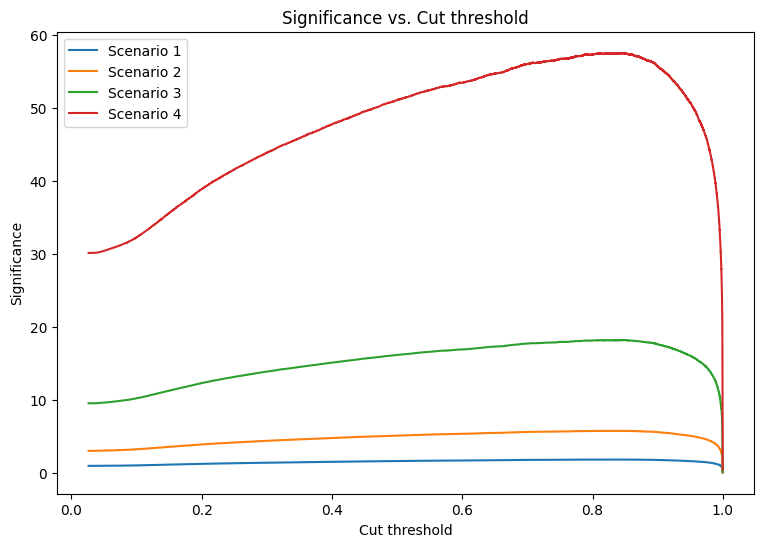

In [26]:
plot_significance(Boosting, VarNames[1:])

### Exercise 5: Metrics

Scikit-learn provides methods for computing the FPR, TPR, ROC, AUC metrics. For example:

In [ ]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_Test, Fisher.decision_function(X_Test))

roc_auc = auc(fpr, tpr)

plt.plot(fpr,tpr,color='darkorange',label='ROC curve (area = %0.2f)' % roc_auc)
plt.legend(loc="lower right")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.show()


#### Part a
TPR/FPR/ROC/AUC are one way of assessing the quality of a classifier. Read about [Precision and Recall](https://en.wikipedia.org/wiki/Precision_and_recall), [Accuracy](https://en.wikipedia.org/wiki/Accuracy_and_precision), and [F-score](https://en.wikipedia.org/wiki/F-score).

#### Part b
Look through [model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html#) documentation. Using scikit-learn's tools, compute TPR, FPR, ROC, AUC, Precision, Recall, F1 score, and accuracy for the method you selected in Exercise 4c and each scenario. Make a nice table, which also includes the maximal significance. 


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_score, recall_score, f1_score, accuracy_score

Best_Model = Boosting
Best_Features = VarNames[1:]

Best_Model.fit(X_Train[Best_Features], y_Train)

scores = Best_Model.predict_proba(X_Test[Best_Features])[:, 1]

fpr, tpr, thresholds = roc_curve(y_Test, scores)
roc_auc = auc(fpr, tpr)

valid = np.isfinite(thresholds)
fpr = fpr[valid]
tpr = tpr[valid]
thresholds = thresholds[valid]

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

results = []

for NS, NB in scenarios:

    NS_selected = tpr * NS
    NB_selected = fpr * NB

    significance = NS_selected / np.sqrt(NS_selected + NB_selected)

    best_index = np.argmax(significance)
    best_cut = thresholds[best_index]

    y_pred = (scores >= best_cut).astype(int)

    sample_weights = np.where(
        y_Test == 1,
        NS / np.sum(y_Test == 1),
        NB / np.sum(y_Test == 0)
    )

    results.append({
        "Scenario": f"{NS}/{NB}",
        "Cut threshold": best_cut,
        "TPR": tpr[best_index],
        "FPR": fpr[best_index],
        "AUC": roc_auc,
        "Precision": precision_score(y_Test, y_pred, sample_weight=sample_weights, zero_division=0),
        "Recall": recall_score(y_Test, y_pred, sample_weight=sample_weights, zero_division=0),
        "F1 score": f1_score(y_Test, y_pred, sample_weight=sample_weights, zero_division=0),
        "Accuracy": accuracy_score(y_Test, y_pred, sample_weight=sample_weights),
        "Max significance": significance[best_index]
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

    Scenario  Cut threshold    TPR    FPR    AUC  Precision  Recall  F1 score  Accuracy  Max significance
      10/100         0.8497 0.4478 0.0157 0.8755     0.7408  0.4478    0.5582    0.9356            1.8214
    100/1000         0.8497 0.4478 0.0157 0.8755     0.7408  0.4478    0.5582    0.9356            5.7596
  1000/10000         0.8497 0.4478 0.0157 0.8755     0.7408  0.4478    0.5582    0.9356           18.2136
10000/100000         0.8497 0.4478 0.0157 0.8755     0.7408  0.4478    0.5582    0.9356           57.5963


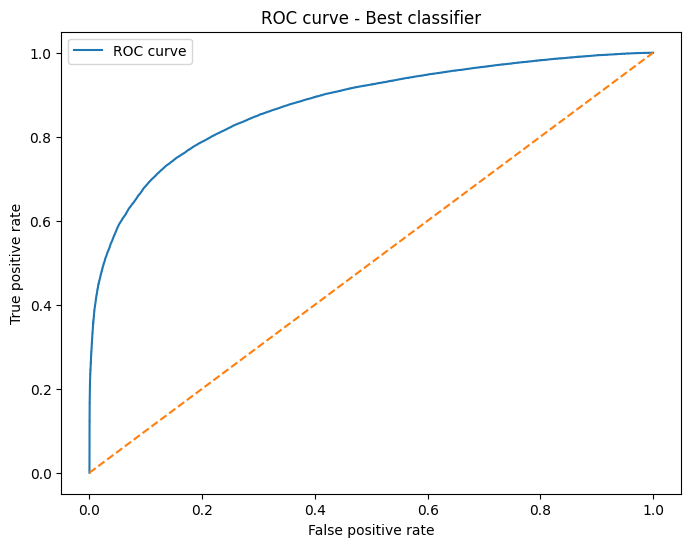

In [29]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label="ROC curve" % roc_auc)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve - Best classifier")
plt.legend()
plt.show()